# Taller Práctica en Colab – Análisis Predictivo

**Universidad de Cundinamarca**  
Especialización en Analítica y Ciencia de Datos  
Business Analytics – Código 604043  

**Estudiante:** Brahan Julian Garcia Solorzano  
**REA 2 – R2-A12-S12**  

---

## Objetivo

Implementar un análisis predictivo sobre un conjunto de datos reales de atenciones en oficinas, aplicando técnicas de regresión lineal para **proyectar comportamientos futuros** y apoyar la toma de decisiones empresariales.

Este notebook sigue los lineamientos de la **Guía Analítica Empresarial (Capítulo Análisis Predictivo)** y el artículo *"What is Predictive Analytics?"*.

## 1. Marco Conceptual

### ¿Qué es el Análisis Predictivo?

El **análisis predictivo** es una rama de la analítica avanzada que utiliza datos históricos, algoritmos estadísticos y técnicas de machine learning para **predecir resultados futuros**. A diferencia del análisis descriptivo —que responde a *"¿qué pasó?"*—, el análisis predictivo responde a *"¿qué podría pasar?"*.

### Elementos clave de un modelo predictivo

1. **Datos históricos:** la base sobre la cual el modelo aprende patrones.  
2. **Variables independientes (features):** las características que alimentan al modelo.  
3. **Variable objetivo (target):** lo que se desea predecir.  
4. **Algoritmo:** el método matemático que encuentra la relación entre features y target.  
5. **Evaluación:** métricas que miden qué tan buenas son las predicciones.

### Aplicación empresarial

En el contexto de **Business Analytics**, un modelo predictivo de atenciones permite:
- Optimizar la asignación de personal según la demanda proyectada.
- Identificar oficinas con tendencias decrecientes para intervención temprana.
- Planificar recursos y presupuestos con base en proyecciones fundamentadas en datos.

---
## 2. Importación de Librerías

Se importan las librerías necesarias para manipulación de datos, modelamiento y visualización.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Configuración visual
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
print('✅ Librerías cargadas correctamente.')

✅ Librerías cargadas correctamente.


---
## 3. Carga y Exploración de Datos

Los datos provienen de la actividad previa de **Obtención de datos** y contienen registros de atenciones diarias por oficina.

In [2]:
# 3.1 Cargar datos
archivo = 'Atenciones.xlsx'
df = pd.read_excel(archivo, sheet_name='Hoja1')

print(f'Dimensiones del dataset: {df.shape[0]} filas x {df.shape[1]} columnas')
print(f'Columnas disponibles: {list(df.columns)}')
df.head(10)

Dimensiones del dataset: 4384 filas x 3 columnas
Columnas disponibles: ['Fecha', 'Oficina', 'Atenciones']


,Fecha,Oficina,Atenciones
0,2025-08-13,Suba,50
1,2025-01-06,Titan,26
2,2023-06-04,Unicentro,77
3,2024-02-10,Titan,210
4,2024-08-05,Unicentro,41
5,2024-12-19,Titan,216
6,2025-04-11,Suba,53
7,2025-07-04,Titan,5
8,2023-05-06,Suba,190
9,2025-06-08,Titan,37


In [3]:
# 3.2 Información general del dataset
print('=== Tipos de datos y valores no nulos ===')
df.info()

=== Tipos de datos y valores no nulos ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4384 entries, 0 to 4383
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Fecha       4384 non-null   datetime64[ns]
 1   Oficina     4384 non-null   object        
 2   Atenciones  4384 non-null   int64         
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 102.9+ KB


In [4]:
# 3.3 Estadísticas descriptivas
print('=== Estadísticas descriptivas ===')
df.describe()

=== Estadísticas descriptivas ===


,Fecha,Atenciones
count,4384,4384.000000
mean,2024-07-01 12:00:00,128.089416
min,2023-01-01 00:00:00,0.000000
25%,2023-10-01 18:00:00,65.000000
50%,2024-07-01 12:00:00,125.000000
75%,2025-04-01 06:00:00,185.000000
max,2025-12-31 00:00:00,389.000000
std,NaN,76.818869


In [5]:
# 3.4 Verificación de calidad de datos
print('=== Valores nulos por columna ===')
print(df.isnull().sum())
print(f'\nFilas duplicadas: {df.duplicated().sum()}')
print(f'Oficinas únicas: {df["Oficina"].nunique()}')
print(df['Oficina'].unique())

=== Valores nulos por columna ===
Fecha         0
Oficina       0
Atenciones    0
dtype: int64

Filas duplicadas: 0
Oficinas únicas: 4
['Suba' 'Titan' 'Unicentro' 'Mall Plaza']


**Interpretación exploratoria:** Con esta exploración inicial se identifican la cantidad de registros, el periodo temporal cubierto, las oficinas disponibles y la existencia (o no) de valores nulos o inconsistencias que deban tratarse antes de modelar.

---
## 4. Preparación y Limpieza de Datos

Se realizan las transformaciones necesarias para que los datos estén listos para el modelo predictivo.

In [6]:
# 4.1 Conversión de la columna Fecha a formato datetime
df['Fecha'] = pd.to_datetime(df['Fecha'], dayfirst=True)

# 4.2 Extracción de variables temporales
df['Año'] = df['Fecha'].dt.year
df['Mes'] = df['Fecha'].dt.month

# 4.3 Eliminar nulos si existen
nulos_antes = df.isnull().sum().sum()
df = df.dropna()
print(f'Valores nulos eliminados: {nulos_antes - df.isnull().sum().sum()}')

# 4.4 Eliminar duplicados
dup = df.duplicated().sum()
df = df.drop_duplicates()
print(f'Duplicados eliminados: {dup}')

# 4.5 Verificar que Atenciones no tenga valores negativos
print(f'Registros con atenciones negativas: {(df["Atenciones"] < 0).sum()}')

print(f'\nDataset limpio: {df.shape[0]} filas x {df.shape[1]} columnas')
df.head()

Valores nulos eliminados: 0
Duplicados eliminados: 0
Registros con atenciones negativas: 0

Dataset limpio: 4384 filas x 5 columnas


,Fecha,Oficina,Atenciones,Año,Mes
0,2025-08-13,Suba,50,2025,8
1,2025-01-06,Titan,26,2025,1
2,2023-06-04,Unicentro,77,2023,6
3,2024-02-10,Titan,210,2024,2
4,2024-08-05,Unicentro,41,2024,8


---
## 5. Selección de Variables Relevantes

Para el modelo predictivo se seleccionan las siguientes variables:

| Variable | Tipo | Rol |
|----------|------|-----|
| `Año` | Numérica | Feature – captura tendencia temporal |
| `Mes` | Categórica (1-12) | Feature – captura estacionalidad |
| `Oficina` | Categórica | Feature – diferencia por ubicación |
| `Atenciones` | Numérica | **Variable objetivo (target)** |

Se aplica **codificación one-hot** a las variables categóricas (`Mes` y `Oficina`) para que el modelo de regresión lineal pueda procesarlas.

In [7]:
# Codificación one-hot
df_model = pd.get_dummies(df[['Año', 'Mes', 'Oficina']], columns=['Mes', 'Oficina'], dtype=int)

X = df_model
y = df['Atenciones']

print(f'Features (X): {X.shape[1]} columnas')
print(f'Target (y): {y.shape[0]} registros')

Features (X): 17 columnas
Target (y): 4384 registros


---
## 6. Aplicación del Modelo Predictivo

### 6.1 División en entrenamiento y prueba

Se divide el dataset en **80% entrenamiento** y **20% prueba** para evaluar el rendimiento del modelo sobre datos que no ha visto.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f'Entrenamiento: {X_train.shape[0]} registros')
print(f'Prueba:        {X_test.shape[0]} registros')

Entrenamiento: 3507 registros
Prueba:        877 registros


### 6.2 Entrenamiento del modelo de Regresión Lineal

Se utiliza **Regresión Lineal Múltiple** de scikit-learn. Este algoritmo busca la combinación lineal de las variables independientes que mejor explique la variable objetivo.

In [9]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

print('✅ Modelo entrenado correctamente.')
print(f'   Intercepto: {modelo.intercept_:.2f}')
print(f'   Coeficientes: {len(modelo.coef_)}')

✅ Modelo entrenado correctamente.
   Intercepto: 5606.25
   Coeficientes: 17


### 6.3 Evaluación del modelo

Se evalúa con métricas estándar de regresión:
- **MAE:** promedio de los errores absolutos.
- **RMSE:** penaliza más los errores grandes.
- **R²:** proporción de la varianza explicada (1.0 = perfecto).

In [10]:
y_pred = modelo.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print('=== Métricas de Evaluación ===')
print(f'  MAE  : {mae:.2f} atenciones')
print(f'  RMSE : {rmse:.2f} atenciones')
print(f'  R²   : {r2:.4f}')

if r2 > 0.7:
    print('\n→ El modelo explica una proporción significativa de la variabilidad.')
elif r2 > 0.4:
    print('\n→ El modelo tiene capacidad predictiva moderada.')
else:
    print('\n→ Capacidad predictiva limitada; se recomienda explorar otros algoritmos.')

=== Métricas de Evaluación ===
  MAE  : 61.95 atenciones
  RMSE : 74.53 atenciones
  R²   : 0.0122

→ Capacidad predictiva limitada; se recomienda explorar otros algoritmos.


---
## 7. Proyección de Atenciones para 2026

Con el modelo entrenado sobre **todos** los datos históricos, se genera la proyección de atenciones para cada oficina durante los 12 meses de 2026.

In [11]:
# Re-entrenar con todos los datos para la proyección final
modelo_final = LinearRegression()
modelo_final.fit(X, y)

# Generar escenario 2026
oficinas = df['Oficina'].unique()
proyeccion_list = []
for mes in range(1, 13):
    for oficina in oficinas:
        proyeccion_list.append({'Año': 2026, 'Mes': mes, 'Oficina': oficina})

df_2026 = pd.DataFrame(proyeccion_list)
df_2026_encoded = pd.get_dummies(df_2026, columns=['Mes', 'Oficina'], dtype=int)
df_2026_encoded = df_2026_encoded.reindex(columns=X.columns, fill_value=0)

predicciones = modelo_final.predict(df_2026_encoded)
df_2026['Atenciones_Proyectadas'] = np.maximum(0, np.round(predicciones)).astype(int)

print('=== Proyección 2026 (primeras 20 filas) ===')
df_2026.head(20)

=== Proyección 2026 (primeras 20 filas) ===


,Año,Mes,Oficina,Atenciones_Proyectadas
0,2026,1,Suba,138
1,2026,1,Titan,112
2,2026,1,Unicentro,116
3,2026,1,Mall Plaza,116
4,2026,2,Suba,151
5,2026,2,Titan,125
6,2026,2,Unicentro,129
7,2026,2,Mall Plaza,128
8,2026,3,Suba,139
9,2026,3,Titan,113


---
## 8. Visualización de Resultados

### 8.1 Valores reales vs. predichos (conjunto de prueba)

Esta gráfica permite evaluar visualmente qué tan cerca están las predicciones de los valores reales. Los puntos cercanos a la línea roja indican buenas predicciones.

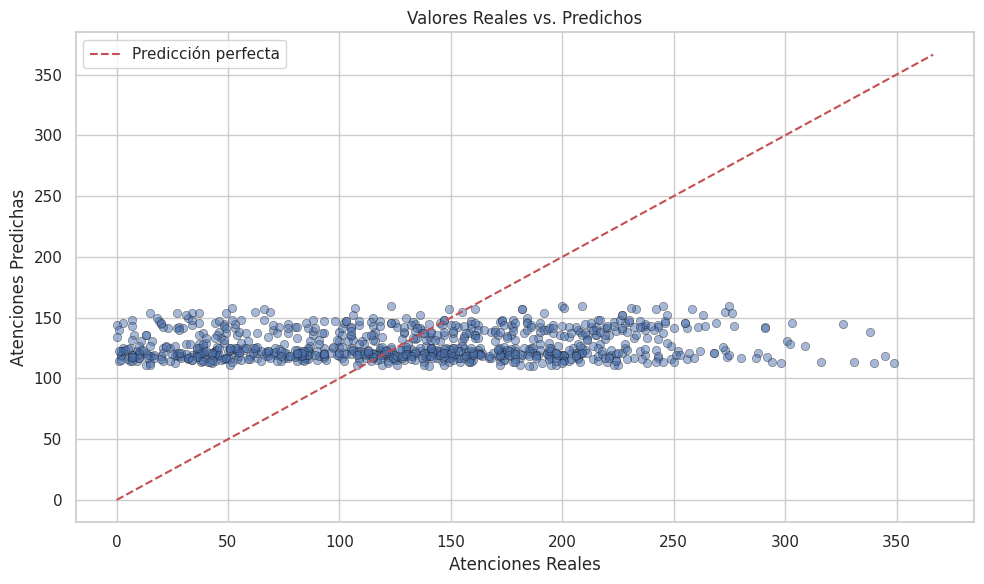

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(y_test, y_pred, alpha=0.5, edgecolors='k', linewidths=0.5)
lim_max = max(y_test.max(), y_pred.max()) * 1.05
ax.plot([0, lim_max], [0, lim_max], 'r--', label='Predicción perfecta')
ax.set_xlabel('Atenciones Reales')
ax.set_ylabel('Atenciones Predichas')
ax.set_title('Valores Reales vs. Predichos')
ax.legend()
plt.tight_layout()
plt.show()

### 8.2 Distribución de errores

Se analiza cómo se distribuyen los errores de predicción. Una distribución centrada en cero indica que el modelo no tiene sesgo sistemático.

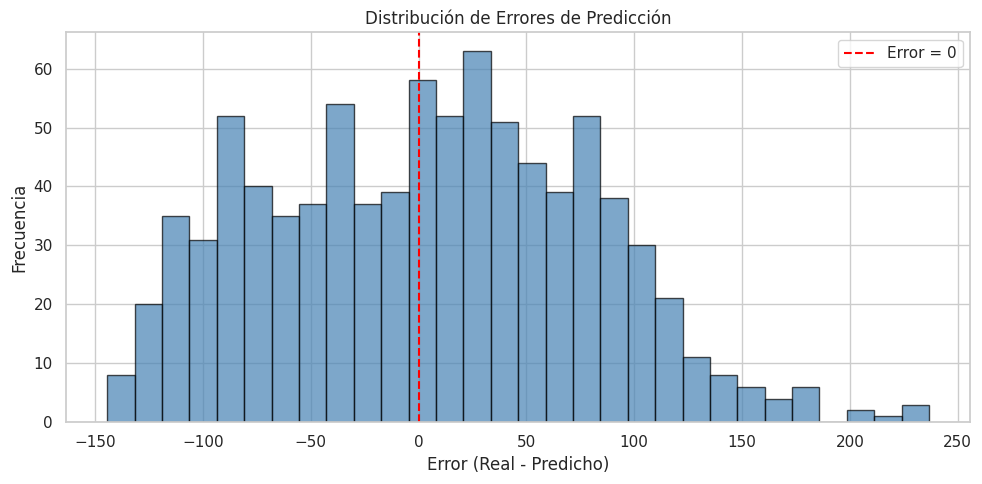

In [13]:
errores = y_test.values - y_pred

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(errores, bins=30, edgecolor='black', alpha=0.7, color='steelblue')
ax.axvline(0, color='red', linestyle='--', label='Error = 0')
ax.set_xlabel('Error (Real - Predicho)')
ax.set_ylabel('Frecuencia')
ax.set_title('Distribución de Errores de Predicción')
ax.legend()
plt.tight_layout()
plt.show()

### 8.3 Histórico mensual de atenciones por oficina

Visualización de la serie temporal histórica que permite identificar patrones de estacionalidad y tendencia por cada oficina.

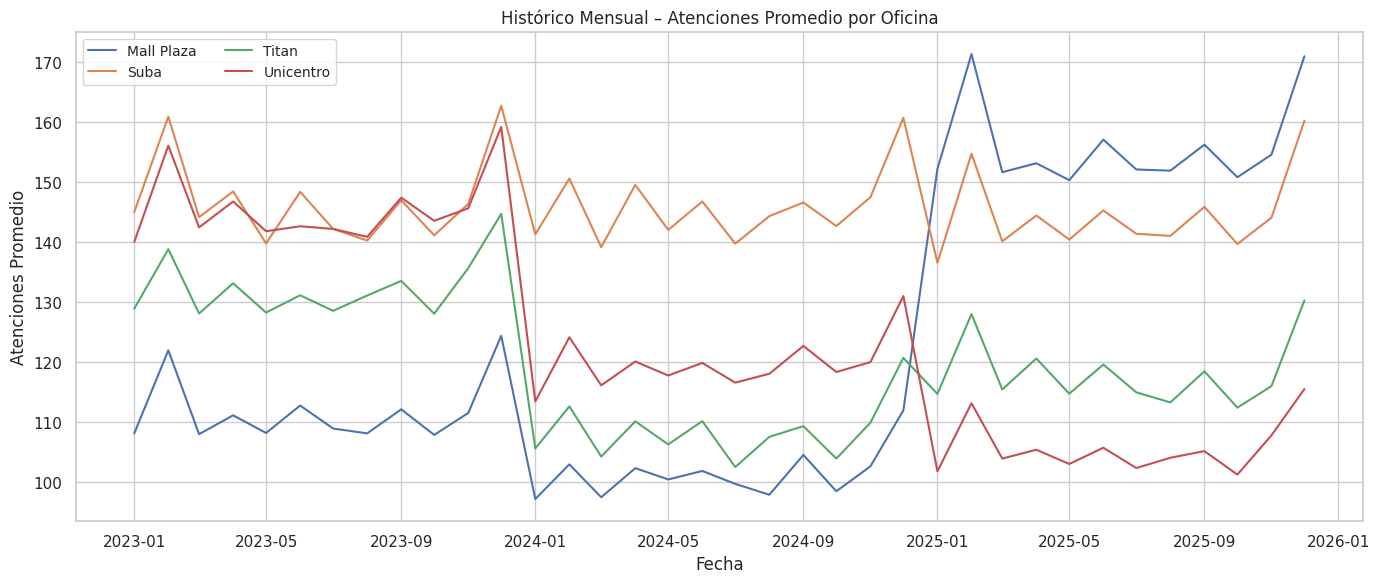

In [14]:
resumen_mensual = df.groupby(['Año', 'Mes', 'Oficina'])['Atenciones'].agg(
    ['mean', 'max', 'min']
).reset_index()
resumen_mensual['Fecha'] = pd.to_datetime(
    dict(year=resumen_mensual['Año'], month=resumen_mensual['Mes'], day=1)
)

fig, ax = plt.subplots(figsize=(14, 6))
for oficina in resumen_mensual['Oficina'].unique():
    subset = resumen_mensual[resumen_mensual['Oficina'] == oficina]
    ax.plot(subset['Fecha'], subset['mean'], label=oficina)

ax.set_xlabel('Fecha')
ax.set_ylabel('Atenciones Promedio')
ax.set_title('Histórico Mensual – Atenciones Promedio por Oficina')
ax.legend(loc='best', fontsize='small', ncol=2)
plt.tight_layout()
plt.show()

### 8.4 Proyección 2026 por oficina

Muestra la demanda proyectada mes a mes para cada oficina, permitiendo anticipar periodos de alta y baja demanda.

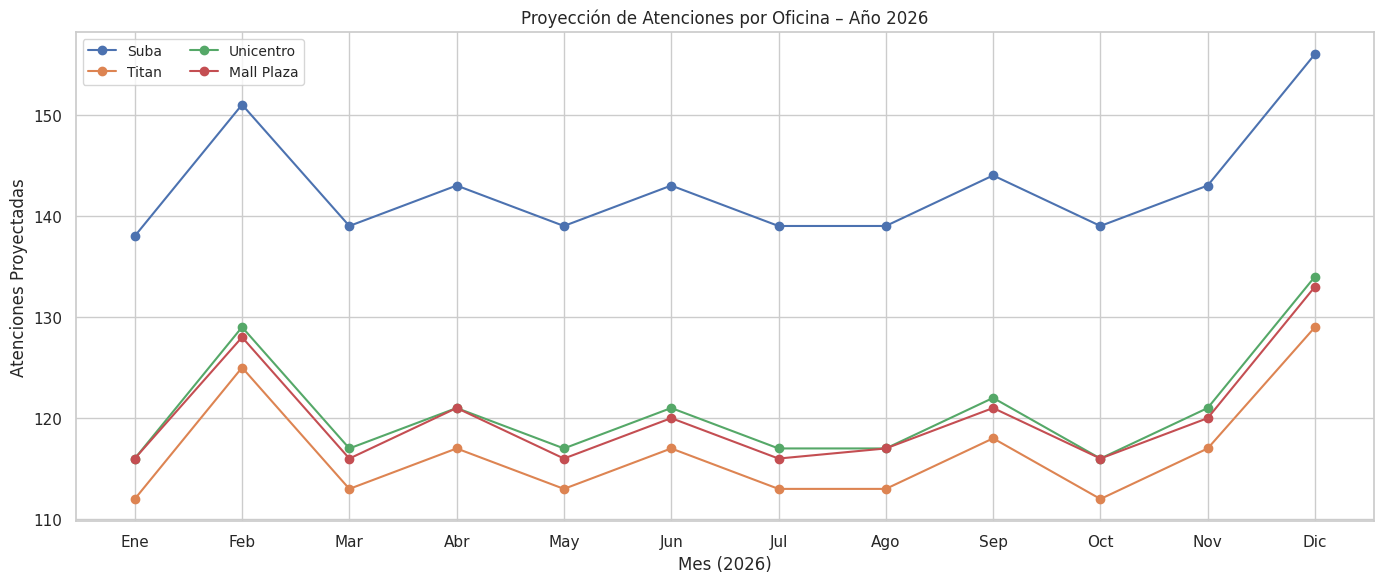

In [15]:
fig, ax = plt.subplots(figsize=(14, 6))
for oficina in df_2026['Oficina'].unique():
    subset = df_2026[df_2026['Oficina'] == oficina]
    ax.plot(subset['Mes'], subset['Atenciones_Proyectadas'], marker='o', label=oficina)

ax.set_xlabel('Mes (2026)')
ax.set_ylabel('Atenciones Proyectadas')
ax.set_title('Proyección de Atenciones por Oficina – Año 2026')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Ene','Feb','Mar','Abr','May','Jun','Jul','Ago','Sep','Oct','Nov','Dic'])
ax.legend(loc='best', fontsize='small', ncol=2)
plt.tight_layout()
plt.show()

### 8.5 Top 5 oficinas con mayor demanda proyectada en 2026

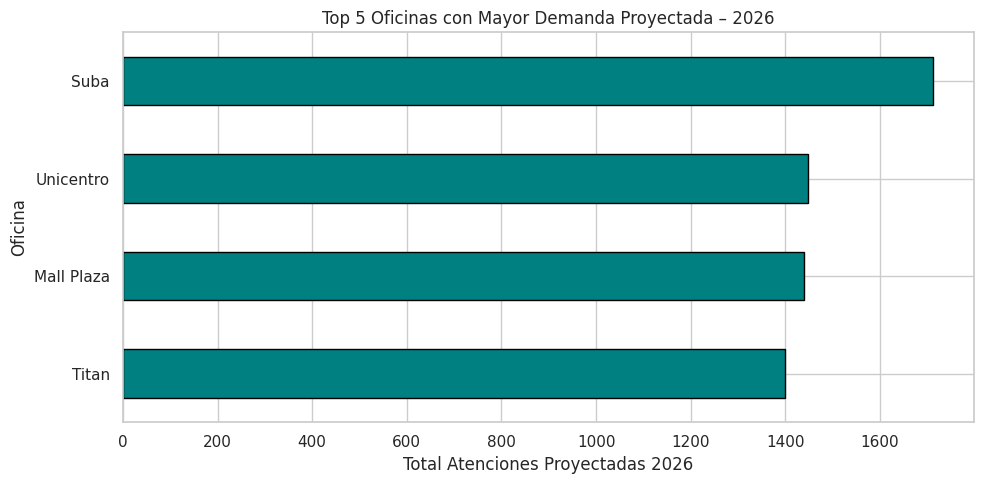

In [16]:
top5 = df_2026.groupby('Oficina')['Atenciones_Proyectadas'].sum().sort_values(ascending=False).head(5)

fig, ax = plt.subplots(figsize=(10, 5))
top5.plot(kind='barh', ax=ax, color='teal', edgecolor='black')
ax.set_xlabel('Total Atenciones Proyectadas 2026')
ax.set_ylabel('Oficina')
ax.set_title('Top 5 Oficinas con Mayor Demanda Proyectada – 2026')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

---
## 9. Exportación del Reporte

Se consolidan los resultados en un archivo Excel con tres hojas.

In [17]:
resumen_anual = df.groupby(['Año', 'Oficina'])['Atenciones'].agg(['mean', 'max', 'min']).reset_index()

with pd.ExcelWriter('Reporte_Final_Con_Proyeccion.xlsx', engine='openpyxl') as writer:
    resumen_mensual.drop(columns='Fecha', errors='ignore').to_excel(
        writer, sheet_name='Historico_Mensual', index=False
    )
    resumen_anual.to_excel(writer, sheet_name='Historico_Anual', index=False)
    df_2026.to_excel(writer, sheet_name='Proyeccion_2026', index=False)

print("✅ Reporte generado: 'Reporte_Final_Con_Proyeccion.xlsx' con 3 hojas.")

✅ Reporte generado: 'Reporte_Final_Con_Proyeccion.xlsx' con 3 hojas.


---
## 10. Interpretación de Resultados y Conclusiones

### Hallazgos principales

1. **Capacidad predictiva:** el R² obtenido permite valorar qué tan bien la regresión lineal captura los patrones. Valores cercanos a 1 indican un buen ajuste; valores más bajos sugieren que factores adicionales (días festivos, campañas, eventos) podrían enriquecer el modelo.

2. **Estacionalidad:** las visualizaciones históricas evidencian patrones mensuales recurrentes, lo que valida el uso del mes como feature clave.

3. **Diferencias entre oficinas:** cada oficina presenta niveles y dinámicas distintas, justificando su inclusión como variable categórica.

4. **Proyección 2026:** las predicciones permiten anticipar la demanda por oficina y mes, facilitando decisiones de **asignación de recursos, turnos de personal y planificación presupuestal**.

### Limitaciones

- La regresión lineal asume una relación lineal entre variables, lo cual puede no capturar dinámicas complejas.
- No se consideran variables exógenas (eventos especiales, campañas de marketing).
- Para producción se recomienda evaluar modelos más avanzados (Random Forest, XGBoost, ARIMA).

### Valor para la toma de decisiones

Este ejercicio demuestra cómo el análisis predictivo convierte datos históricos en **insumos accionables** para la planificación empresarial, alineándose con los principios de la Guía Analítica Empresarial.

---
## Enlace al Repositorio

https://github.com/bjgarcia20/analisis_predictivo_business_analytics.git

---
## Referencias

- Guía Analítica Empresarial – Capítulo Análisis Predictivo. Universidad de Cundinamarca.
- *"What is Predictive Analytics?"* – Material de referencia del curso Business Analytics.
- Scikit-learn Documentation: https://scikit-learn.org/stable/